# 01. DETAW Theory & Interactive Walkthrough

This tutorial introduces the physical theory and step-by-step calculations of **DETAW (*Delta Evapotranspiration of Applied Water*)** as formulated by **Snyder et al. (2006)** (*DETAW v1.0 Final Report*, UC Davis & California Department of Water Resources) and implemented in `deltacd.detaw` using `xarray` and `pandas`.

## Learning Objectives
1. **Reference Evapotranspiration ($ET_0$)**: Compute extraterrestrial solar radiation ($R_a$) and compare **Hargreaves–Samani** vs. **ASCE Standardized Penman–Monteith** $ET_0$ (Snyder et al., Appendix B).
2. **Two-Stage Bare-Soil Evaporation ($OK_c$)**: Understand how winter rainfall frequency controls off-season bare-soil evaporation (Ventura et al., 2006; Snyder et al., Appendix C).
3. **Seasonal Crop Coefficients ($IK_c$ & $K_c$)**: Compare **Critical** vs. **Non-Critical** water-year $K_c$ curves across growth stages A–B–C–D–E.
4. **Daily Root-Zone Soil Water Balance**: Inspect effective seepage ($S_e$), effective rainfall ($E_r$), soil water depletion ($SWD$), and management allowable depletion ($SWD_x$) irrigation events ($NA$).
5. **Smoothed $ET_{aw}$ vs. Discrete Irrigation Events ($NA$)**: See how DETAW converts field-scale irrigation spikes into smooth daily water demand for **DCD** channel routing across contrasting land uses (Tomato, Irrigated Grain, Rice, Riparian Vegetation, Native Vegetation, and Open Water).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from deltacd.detaw import (
    DetawConfig,
    KcETcProvider,
    StationMeteorologyProvider,
    compute_smoothed_etaw,
    read_crop_params,
    read_landuse,
    read_subarea_params,
    run_soil_water_balance,
)

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
REPO_ROOT = Path("..").resolve() if Path("../examples").exists() else Path(".").resolve()
print("Repository root:", REPO_ROOT)

Repository root: /scratch/knam/repos/deltacd


## 1. Extraterrestrial Radiation ($R_a$) & Reference Evapotranspiration ($ET_0$)

In DETAW (**Snyder et al., 2006, Appendix B, pp. 69–71**), daily reference evapotranspiration $ET_0$ ($\text{mm d}^{-1}$) represents evaporative demand over a well-watered, 0.12 m tall cool-season grass canopy.

Because long-term historical records back to Oct 1921 only have daily maximum ($T_x$) and minimum ($T_n$) air temperatures at Lodi, DETAW estimates station $ET_0$ with the **Hargreaves–Samani (1985)** equation:

$$ET_h = \frac{0.0023}{\lambda} R_a \sqrt{T_x - T_n}\,(T_m + 17.8), \qquad \lambda = 2.45\text{ MJ kg}^{-1}$$

and multiplies by a subarea spatial regression slope (`eto_correction`, calibrated against 9 Delta **CIMIS** stations where **ASCE Standardized Penman–Monteith** $ET_0$ was computed from solar radiation, wind speed, temperature, and humidity).

<xarray.Dataset> Size: 41kB
Dimensions:  (time: 731, subarea: 3)
Coordinates:
  * time     (time) datetime64[ns] 6kB 1993-09-30 1993-10-01 ... 1995-09-30
  * subarea  (subarea) int64 24B 1 2 3
Data variables:
    et0      (time, subarea) float64 18kB 4.768 4.733 4.794 ... 4.11 4.079 4.132
    precip   (time, subarea) float64 18kB 0.0 0.0 0.0 0.0 ... 0.3286 0.0 0.0 0.0
Attributes:
    has_spinup_day:  1


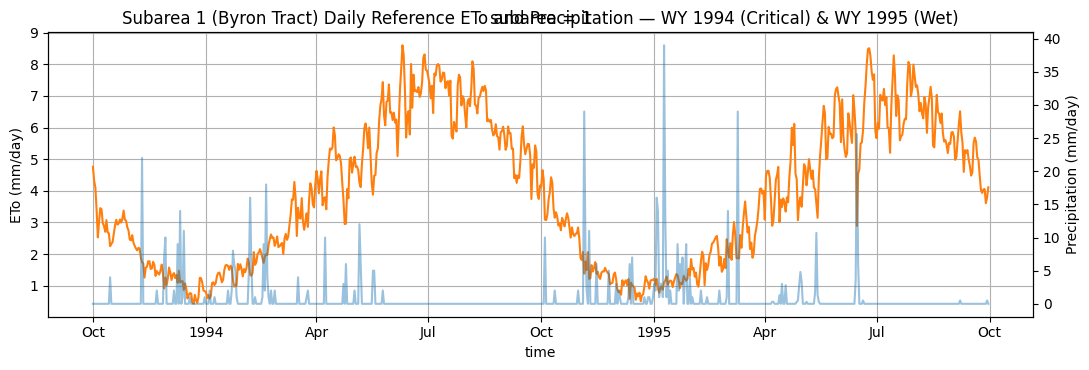

In [2]:
cfg = DetawConfig.from_yaml(REPO_ROOT / "examples" / "detaw_ex1.yaml")
cfg.start_water_year = 1994  # WY 1994 = Critical ('C'), WY 1995 = Wet ('W')
cfg.end_water_year = 1995

ds_lu = read_landuse(cfg.landuse_path, water_years=[1994, 1995])
ds_cp = read_crop_params(
    cfg.critical_crop_path, cfg.noncritical_crop_path, target_crops=ds_lu["crop"].values
)
ds_sub = read_subarea_params(cfg.et_correction_path, subareas=ds_lu["subarea"].values)
ds_meteo = StationMeteorologyProvider(cfg).load(1994, 1995, ds_sub)

print(ds_meteo)

fig, ax = plt.subplots(figsize=(11, 3.8))
ds_meteo["et0"].sel(subarea=1, time=slice("1993-10-01", "1995-09-30")).plot(
    ax=ax, label="Subarea 1 ETo (mm/d)", color="tab:orange"
)
ax2 = ax.twinx()
ds_meteo["precip"].sel(subarea=1, time=slice("1993-10-01", "1995-09-30")).plot(
    ax=ax2, label="Precipitation (mm/d)", color="tab:blue", alpha=0.45
)
ax.set_title(
    "Subarea 1 (Byron Tract) Daily Reference ETo and Precipitation — WY 1994 (Critical) & WY 1995 (Wet)"
)
ax.set_ylabel("ETo (mm/day)")
ax2.set_ylabel("Precipitation (mm/day)")
ax2.grid(False)
plt.tight_layout()
plt.show()

## 2. Two-Stage Bare-Soil Evaporation ($OK_c$) & Seasonal Crop Coefficients ($K_c$)

During winter and early crop growth, bare-soil evaporation dominates. Following **Ventura et al. (2006)** (**Snyder et al., Appendix C, pp. 72–75**), cumulative maximum soil evaporation $CE_x = (1.22 - 0.04\,\overline{ET_0})\,CET_0$ transitions from energy-limited **Stage 1** ($CE_s = CE_x$) to soil-hydraulics-limited **Stage 2** ($CE_s = \beta\sqrt{CE_x}$, $\beta = 2.6$) whenever $\sqrt{CE_x} \ge \beta$, resetting whenever significant rainfall ($P > \overline{ET_0}$) rewets the topsoil.

On every day, a crop's effective coefficient is bounded below by bare-soil evaporation:

$$K_c(t) = \max\bigl(IK_c(t),\, OK_c(t)\bigr)$$

Notice below how **WY 1994 (`C`, Critical)** and **WY 1995 (`W`, Wet)** produce distinct $IK_c$ curves and rainfall-driven winter $OK_c$ spikes.

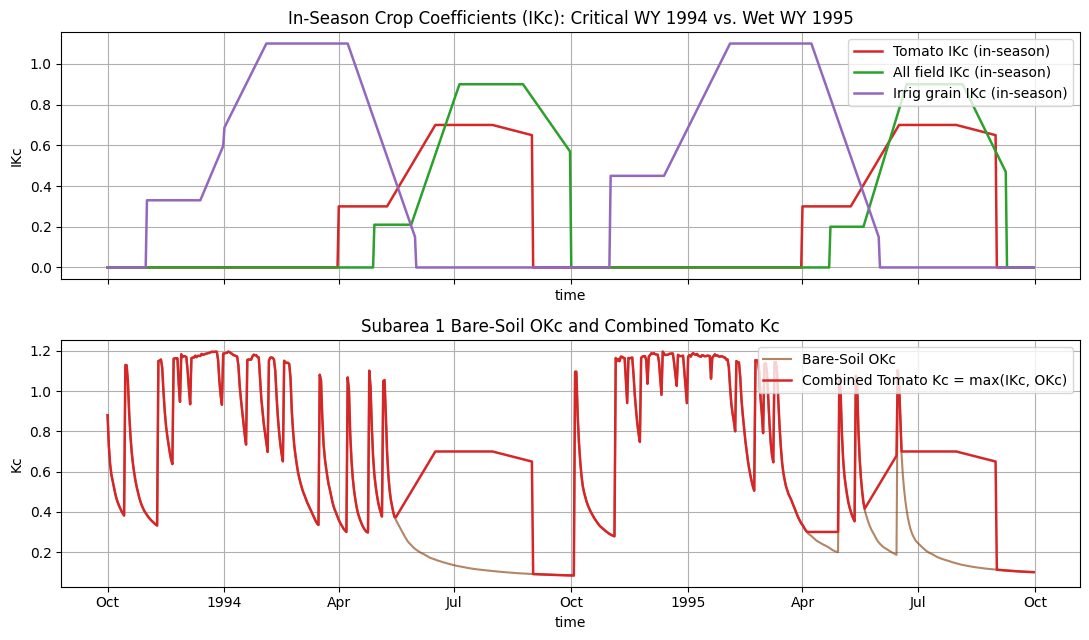

In [3]:
time_idx = pd.date_range("1993-10-01", "1995-09-30", freq="D")
ds_et = KcETcProvider(cfg).compute(time_idx, ds_meteo, ds_cp, ds_lu["year_type"])

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for crop_name, color in [
    ("Tomato", "tab:red"),
    ("All field", "tab:green"),
    ("Irrig grain", "tab:purple"),
]:
    ds_et["ikc"].sel(crop=crop_name).plot(
        ax=axes[0], label=f"{crop_name} IKc (in-season)", lw=1.8, color=color
    )
axes[0].set_title("In-Season Crop Coefficients (IKc): Critical WY 1994 vs. Wet WY 1995")
axes[0].set_ylabel("IKc")
axes[0].legend(loc="upper right")

ds_et["okc"].sel(subarea=1).plot(ax=axes[1], label="Bare-Soil OKc", color="saddlebrown", alpha=0.65)
ds_et["kc"].sel(subarea=1, crop="Tomato").plot(
    ax=axes[1], label="Combined Tomato Kc = max(IKc, OKc)", color="tab:red", lw=1.8
)
axes[1].set_title("Subarea 1 Bare-Soil OKc and Combined Tomato Kc")
axes[1].set_ylabel("Kc")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 3. Root-Zone Soil Water Balance & Irrigation Scheduling

For agricultural crops (**Snyder et al., pp. 28–30, 33–37**), daily soil water depletion ($SWD$, $\text{mm}$ below field capacity $FC$) evolves as:

$$D_{sw} = ET_c - E_{spg} - E_r, \qquad SWD_t = \max(0,\, SWD_{t-1} + D_{sw,t} - NA_t)$$

where:
- **Effective seepage ($E_{spg}$)**: Lowland islands receive subsurface channel seepage up to $0.025 \cdot \text{erd} / N_{\text{days}}$ per day ($0.15$ for riparian/native vegetation; $0$ in uplands).
- **Effective rainfall ($E_r$)**: Rainfall refills root-zone depletion up to field capacity ($SWD = 0$); excess rainfall becomes runoff handled in DCD.
- **Net application ($NA$)**: During the growing season (`IKc > 0`), whenever $SWD_{t-1} + D_{sw,t} > SWD_x$, irrigation refills the root zone back to field capacity ($NA_t = SWD_{t-1} + D_{sw,t}$, resetting $SWD_t = 0$).

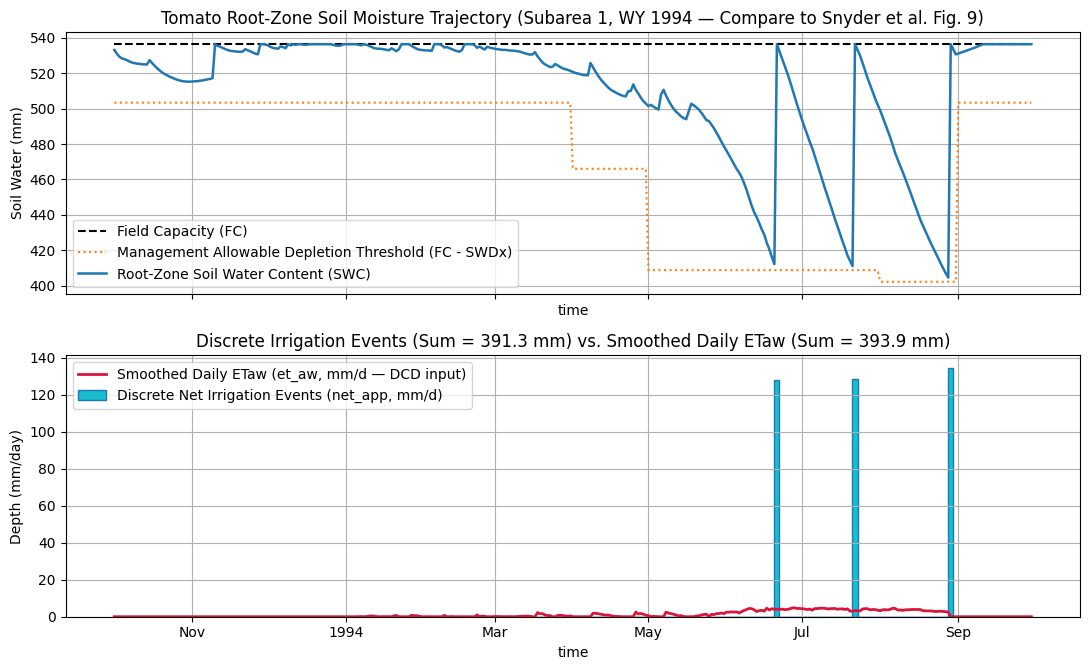

In [4]:
ds_wb = run_soil_water_balance(
    ds_et=ds_et,
    ds_crop_params=ds_cp,
    ds_subarea=ds_sub,
    da_year_type=ds_lu["year_type"],
)
da_etaw_mm = compute_smoothed_etaw(ds_wb, ds_cp)

# Plot Tomato root-zone soil water content (SWC), Field Capacity (FC), and irrigation events in WY 1994
tom_94 = ds_wb.sel(subarea=1, crop="Tomato", time=slice("1993-10-01", "1994-09-30"))
etaw_94 = da_etaw_mm.sel(subarea=1, crop="Tomato", time=slice("1993-10-01", "1994-09-30"))

fig, axes = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True)
tom_94["fc_mm"].plot(ax=axes[0], label="Field Capacity (FC)", ls="--", color="black")
(tom_94["fc_mm"] - tom_94["swdx_mm"]).plot(
    ax=axes[0],
    label="Management Allowable Depletion Threshold (FC - SWDx)",
    ls=":",
    color="tab:orange",
)
tom_94["swc_mm"].plot(
    ax=axes[0], label="Root-Zone Soil Water Content (SWC)", color="tab:blue", lw=1.8
)
axes[0].set_title(
    "Tomato Root-Zone Soil Moisture Trajectory (Subarea 1, WY 1994 — Compare to Snyder et al. Fig. 9)"
)
axes[0].set_ylabel("Soil Water (mm)")
axes[0].legend(loc="lower left")

axes[1].bar(
    tom_94["time"].values,
    tom_94["net_app_mm"].values,
    width=2.0,
    color="tab:cyan",
    edgecolor="tab:blue",
    label="Discrete Net Irrigation Events (net_app, mm/d)",
)
etaw_94.plot(
    ax=axes[1], color="crimson", lw=2.0, label="Smoothed Daily ETaw (et_aw, mm/d — DCD input)"
)
axes[1].set_title(
    f"Discrete Irrigation Events (Sum = {float(tom_94['net_app_mm'].sum()):.1f} mm) vs. Smoothed Daily ETaw (Sum = {float(etaw_94.sum()):.1f} mm)"
)
axes[1].set_ylabel("Depth (mm/day)")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

## 4. Comparing Special Land-Use Categories Across Subarea 1

DETAW models 15–16 land-use categories via declarative `CropBehavior` rules (`deltacd.detaw.params`):
- **Irrigated Row/Field/Orchard Crops (`TO`, `FI`, `OR`, `GR`, ...)**: Threshold-scheduled irrigation (`NA > 0` when `SWD + Dsw > SWDx`).
- **Rice (`RI`)**: Continuous paddy flooding (`NA = SWD + Dsw` daily) until 20 days prior to harvest, when paddies are drained.
- **Riparian Vegetation (`RV`)**: In lowlands, fully supplied by channel seepage (`Espg = ETc`, `Dsw = 0`, `et_aw = 0`).
- **Native Vegetation (`NV`) & Non-Irrigated Grain (`DGR`)**: Rain- and seepage-fed only (`is_irrigated = False`, `et_aw = 0`).
- **Water Surface (`WS`)**: Open-water evaporation (`Kc = 1.1`), routed in DCD as `depletion_from_waterbody`.

In [5]:
wy94_wb = ds_wb.sel(subarea=1, time=slice("1993-10-01", "1994-09-30"))
wy94_etaw = da_etaw_mm.sel(subarea=1, time=slice("1993-10-01", "1994-09-30"))

summary_rows = []
for crop_name in [
    "Tomato",
    "All field",
    "Irrig grain",
    "Rice",
    "Riparian vegetation",
    "Native vegetation",
    "Water surface",
]:
    c_wb = wy94_wb.sel(crop=crop_name)
    summary_rows.append(
        {
            "Crop": crop_name,
            "ETc (mm/yr)": round(float(c_wb["et_c_mm"].sum()), 1),
            "Eff. Seepage Se (mm/yr)": round(float(c_wb["s_e_mm"].sum()), 1),
            "Eff. Rain Er (mm/yr)": round(float(c_wb["e_r_mm"].sum()), 1),
            "Net Irrig NA (mm/yr)": round(float(c_wb["net_app_mm"].sum()), 1),
            "Smoothed ETaw (mm/yr)": round(float(wy94_etaw.sel(crop=crop_name).sum()), 1),
        }
    )

df_summary = pd.DataFrame(summary_rows).set_index("Crop")
df_summary

,ETc (mm/yr),Eff. Seepage Se (mm/yr),Eff. Rain Er (mm/yr),Net Irrig NA (mm/yr),Smoothed ETaw (mm/yr)
Crop,,,,,
Tomato,868.9,351.2,126.5,391.3,393.9
All field,1009.5,183.0,192.8,630.2,623.9
Irrig grain,640.5,183.0,148.0,248.2,261.1
Rice,1194.2,56.8,219.2,840.1,788.5
Riparian vegetation,1272.9,1272.9,0.0,0.0,0.0
Native vegetation,899.5,897.7,1.8,0.0,0.0
Water surface,1606.2,0.0,236.0,0.0,0.0
